<a href="https://colab.research.google.com/github/SamiraSalema/dataview-projeto/blob/main/MOv_Analise_Preditiva_SCTEC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MOv — Análise de Preferências Turísticas

Projeto: Desenvolvimento de IA para Análise Preditiva — SCTEC

Objetivo: investigar dados de avaliações turísticas e desenvolver um modelo de aprendizado de máquina que possa contribuir para a personalização de experiências na futura plataforma MOv, voltada ao turismo em Navegantes, Santa Catarina.

Fase 1 - Seleção e Exploração dos dados.

In [2]:
%pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

print("Biblioteca carregada com sucesso!")

Biblioteca carregada com sucesso!


In [4]:
base = fetch_ucirepo(id=484)

X = base.data.features

display(X.head())

,Category 1,Category 2,Category 3,Category 4,Category 5,Category 6,Category 7,Category 8,Category 9,Category 10
0,0.93,1.8,2.29,0.62,0.80,2.42,3.19,2.79,1.82,2.42
1,1.02,2.2,2.66,0.64,1.42,3.18,3.21,2.63,1.86,2.32
2,1.22,0.8,0.54,0.53,0.24,1.54,3.18,2.80,1.31,2.50
3,0.45,1.8,0.29,0.57,0.46,1.52,3.18,2.96,1.57,2.86
4,0.51,1.2,1.18,0.57,1.54,2.02,3.18,2.78,1.18,2.54


Etapa 1.2 — Análise exploratória dos dados

Nesta etapa, vamos conhecer a estrutura da base, verificar a quantidade de registros, identificar os tipos de dados e conferir a existência de valores ausentes. Essa análise ajudará a decidir como preparar os dados para o modelo de aprendizado de máquina.

In [5]:
# Quantidade de linhas e colunas
print("Formato da base:", X.shape)

# Tipos de dados de cada coluna
print("\nTipos de dados:")
print(X.dtypes)

# Verificar valores ausentes
print("\nValores ausentes por coluna:")
print(X.isnull().sum())

# Estatísticas básicas
print("\nResumo estatístico:")
display(X.describe())

Formato da base: (980, 10)

Tipos de dados:
Category 1     float64
Category 2     float64
Category 3     float64
Category 4     float64
Category 5     float64
Category 6     float64
Category 7     float64
Category 8     float64
Category 9     float64
Category 10    float64
dtype: object

Valores ausentes por coluna:
Category 1     0
Category 2     0
Category 3     0
Category 4     0
Category 5     0
Category 6     0
Category 7     0
Category 8     0
Category 9     0
Category 10    0
dtype: int64

Resumo estatístico:


,Category 1,Category 2,Category 3,Category 4,Category 5,Category 6,Category 7,Category 8,Category 9,Category 10
count,980.000000,980.000000,980.000000,980.000000,980.000000,980.000000,980.000000,980.000000,980.000000,980.000000
mean,0.893194,1.352612,1.013306,0.532500,0.939735,1.842898,3.180939,2.835061,1.569439,2.799224
std,0.326912,0.478280,0.788607,0.279731,0.437430,0.539538,0.007824,0.137505,0.364629,0.321380
min,0.340000,0.000000,0.130000,0.150000,0.060000,0.140000,3.160000,2.420000,0.740000,2.140000
25%,0.670000,1.080000,0.270000,0.410000,0.640000,1.460000,3.180000,2.740000,1.310000,2.540000
50%,0.830000,1.280000,0.820000,0.500000,0.900000,1.800000,3.180000,2.820000,1.540000,2.780000
75%,1.020000,1.560000,1.572500,0.580000,1.200000,2.200000,3.180000,2.910000,1.760000,3.040000
max,3.220000,3.640000,3.620000,3.440000,3.300000,3.760000,3.210000,3.390000,3.170000,3.660000


## **Fonte e características da base**

Nome: Travel Reviews

Fonte: UCI Machine Learning Repository

Origem: avaliações do TripAdvisor sobre dez categorias de destinos na Ásia Oriental.

Dimensão: 980 registros e 10 variáveis numéricas.

Escala: avaliações médias entre 0 e 4.

Valores ausentes: nenhum identificado na análise inicial.

Limitação: os dados não representam diretamente os turistas de Navegantes. Os padrões encontrados serão utilizados como estudo inicial para a futura personalização da MOv.

Referência: Renjith, S. (2018). Travel Reviews. UCI Machine Learning Repository. https://doi.org/10.24432/C56K6W

In [8]:
display(base.variables)

,name,role,type,demographic,description,units,missing_values
0,User ID,ID,Categorical,None,None,None,no
1,Category 1,Feature,Continuous,None,Average user feedback on art galleries,None,no
2,Category 2,Feature,Continuous,None,Average user feedback on dance clubs,None,no
3,Category 3,Feature,Continuous,None,Average user feedback on juice bars,None,no
4,Category 4,Feature,Continuous,None,Average user feedback on restaurants,None,no
5,Category 5,Feature,Continuous,None,Average user feedback on museums,None,no
6,Category 6,Feature,Continuous,None,Average user feedback on resorts,None,no
7,Category 7,Feature,Continuous,None,Average user feedback on parks/picnic spots,None,no
8,Category 8,Feature,Continuous,None,Average user feedback on beaches,None,no
9,Category 9,Feature,Continuous,None,Average user feedback on theaters,None,no


Etapa 1.3 — Preparação inicial das variáveis

Nesta etapa, vamos criar uma cópia da base de dados e renomear as dez variáveis para facilitar sua interpretação no projeto MOv.

A coluna User ID não será incluída no treinamento, pois serve apenas para identificar os usuários. As variáveis utilizadas serão as avaliações médias de dez categorias de experiências turísticas.

Essa organização facilitará as próximas etapas de análise exploratória, preparação dos dados, treinamento e avaliação do modelo de agrupamento.

In [9]:
# Criar uma cópia das variáveis que serão utilizadas
X_model = X.copy()

# Renomear as colunas para facilitar a interpretação
X_model.columns = [
    "galerias_arte",
    "clubes_danca",
    "bares_sucos",
    "restaurantes",
    "museus",
    "resorts",
    "parques_pícnic",
    "praias",
    "teatros",
    "instituicoes_religiosas"
]

# Mostrar as primeiras linhas da base organizada
display(X_model.head())

# Conferir as estatísticas das variáveis
print("Resumo das variáveis:")
display(X_model.describe().T[["mean", "std", "min", "max"]])

,galerias_arte,clubes_danca,bares_sucos,restaurantes,museus,resorts,parques_pícnic,praias,teatros,instituicoes_religiosas
0,0.93,1.8,2.29,0.62,0.80,2.42,3.19,2.79,1.82,2.42
1,1.02,2.2,2.66,0.64,1.42,3.18,3.21,2.63,1.86,2.32
2,1.22,0.8,0.54,0.53,0.24,1.54,3.18,2.80,1.31,2.50
3,0.45,1.8,0.29,0.57,0.46,1.52,3.18,2.96,1.57,2.86
4,0.51,1.2,1.18,0.57,1.54,2.02,3.18,2.78,1.18,2.54


Resumo das variáveis:


,mean,std,min,max
galerias_arte,0.893194,0.326912,0.34,3.22
clubes_danca,1.352612,0.478280,0.00,3.64
bares_sucos,1.013306,0.788607,0.13,3.62
restaurantes,0.532500,0.279731,0.15,3.44
museus,0.939735,0.437430,0.06,3.30
resorts,1.842898,0.539538,0.14,3.76
parques_pícnic,3.180939,0.007824,3.16,3.21
praias,2.835061,0.137505,2.42,3.39
teatros,1.569439,0.364629,0.74,3.17
instituicoes_religiosas,2.799224,0.321380,2.14,3.66


**Fase 2. Próxima etapa — visualizar a distribuição das avaliações**

Antes de escolher os parâmetros do modelo, vamos visualizar como os dados se distribuem. Isso faz parte da análise exploratória de dados (EDA) e ajuda a entender o que estamos oferecendo ao algoritmo.

**Etapa 1.4 — Visualização da distribuição dos dados**

Vamos utilizar histogramas para observar a distribuição das avaliações em cada categoria turística.

Essa visualização permite identificar concentrações de valores, diferenças entre categorias e possíveis padrões que mereçam investigação antes do treinamento do modelo.

Nesta etapa, ainda não estamos treinando a inteligência artificial. Estamos conhecendo os dados que serão utilizados no projeto MOv.

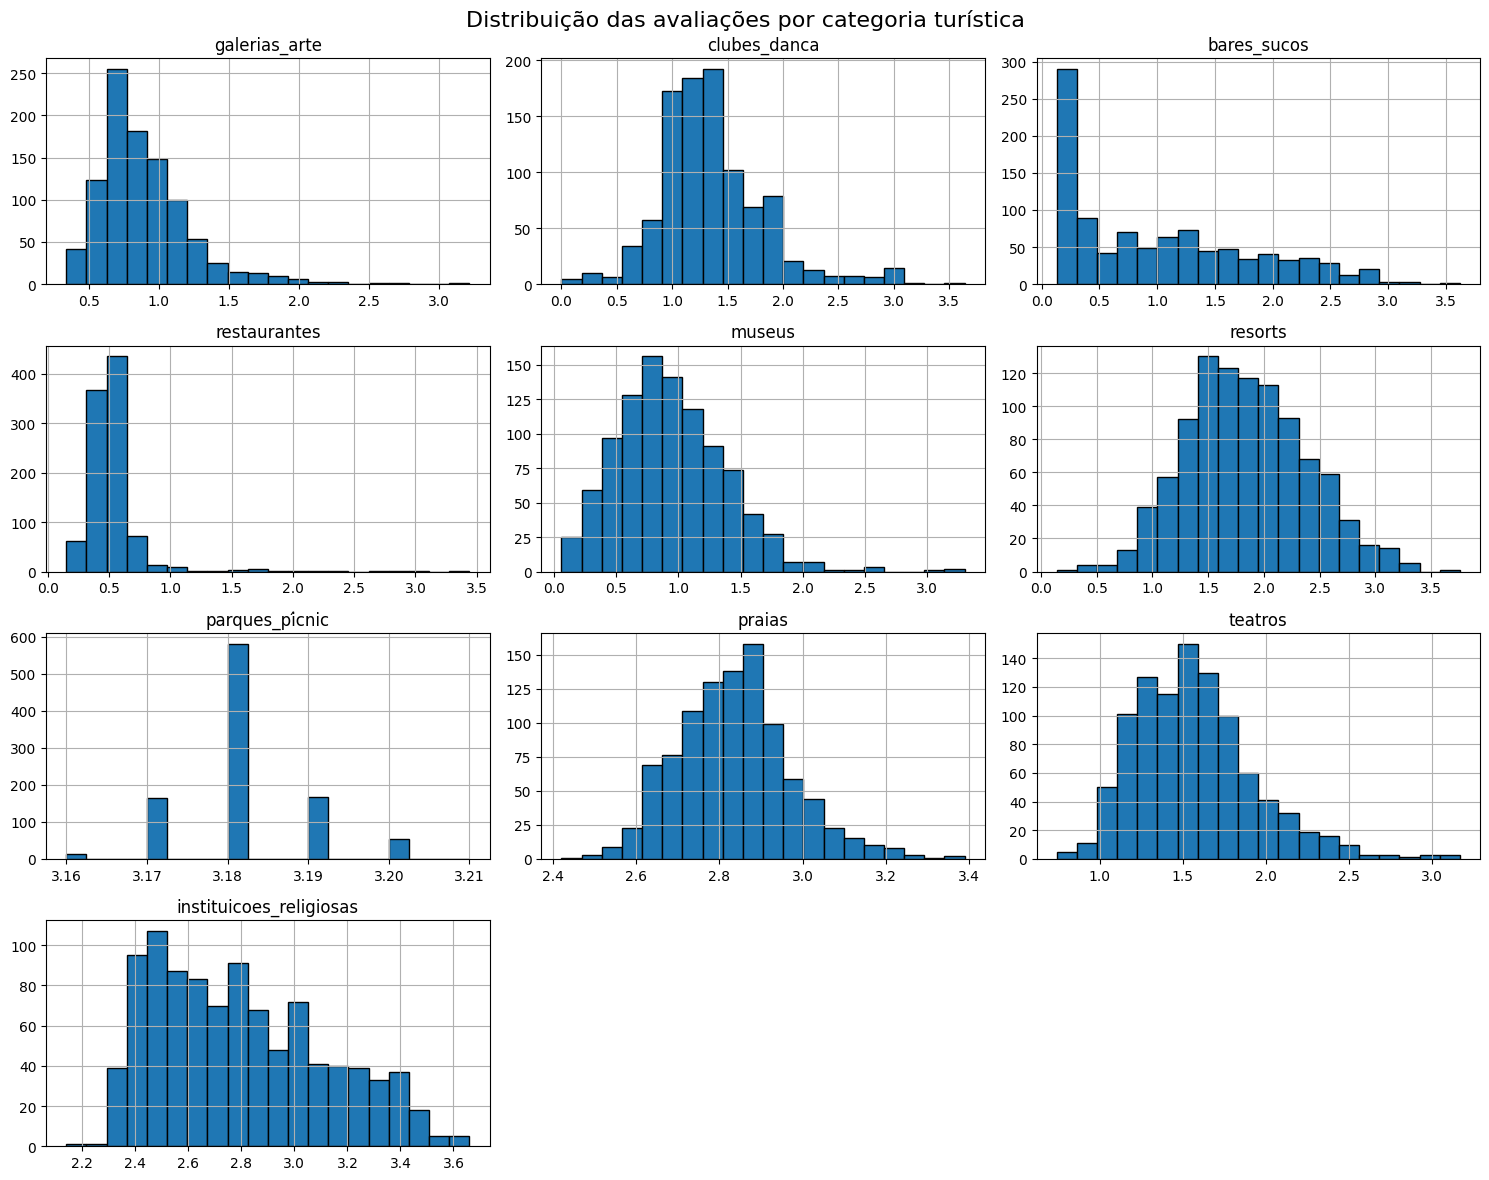

In [10]:
import matplotlib.pyplot as plt

# Criar histogramas para as dez categorias
X_model.hist(figsize=(15, 12), bins=20, edgecolor="black")

plt.suptitle(
    "Distribuição das avaliações por categoria turística",
    fontsize=16
)

plt.tight_layout()
plt.show()

**Etapa 1.5 — Separação dos dados e padronização**

O K-Means utiliza distâncias para agrupar registros semelhantes. Por isso, vamos padronizar as variáveis numéricas, colocando-as em escalas comparáveis.

Também separaremos os registros em três conjuntos:

Treino: utilizado para ajustar o modelo.

Validação: utilizado para comparar configurações do algoritmo.

Teste: reservado para avaliar a configuração escolhida.

Como esta base não possui uma variável-alvo, não utilizaremos acurácia ou F1-score. Para o agrupamento, investigaremos a métrica silhouette score, que mede o quanto os registros estão próximos do próprio grupo em comparação com os demais. Valores maiores geralmente indicam grupos mais bem separados, mas a métrica não garante recomendações turísticas úteis.

In [12]:
# Importar a função responsável pela separação dos dados
from sklearn.model_selection import train_test_split

# Separar 20% dos dados para o teste final
X_temp, X_test = train_test_split(
    X_model,
    test_size=0.20,
    random_state=42
)

# Separar os dados restantes entre treino e validação
X_train, X_val = train_test_split(
    X_temp,
    test_size=0.25,
    random_state=42
)

# Conferir os tamanhos dos conjuntos
print("Quantidade de registros:")
print("Treino:", len(X_train))
print("Validação:", len(X_val))
print("Teste:", len(X_test))

print("\nTotal:", len(X_train) + len(X_val) + len(X_test))

Quantidade de registros:
Treino: 588
Validação: 196
Teste: 196

Total: 980


**Etapa 1.6 — Padronização dos dados**

O K-Means agrupa registros usando distâncias. Quando as variáveis apresentam escalas ou variações diferentes, isso pode influenciar a formação dos grupos.

Vamos usar o StandardScaler, que transforma as variáveis para que tenham média próxima de zero e desvio-padrão próximo de um, calculados com base nos dados de treino.

**Etapa 1.6 — Padronização das variáveis**


Nesta etapa, vamos padronizar as dez variáveis de avaliação turística usando o StandardScaler, do Scikit-learn.

O ajuste será realizado exclusivamente com os dados de treino. Depois, o mesmo transformador será aplicado aos dados de validação e teste, sem reajustá-lo. Esse procedimento ajuda a evitar vazamento de dados (data leakage) e prepara os conjuntos para o treinamento e a avaliação do modelo K-Means.

In [13]:
from sklearn.preprocessing import StandardScaler

# Criar o padronizador
scaler = StandardScaler()

# Aprender os parâmetros somente com os dados de treino
X_train_scaled = scaler.fit_transform(X_train)

# Aplicar os mesmos parâmetros aos outros conjuntos
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Conferir as dimensões dos conjuntos padronizados
print("Dimensões após a padronização:")
print("Treino:", X_train_scaled.shape)
print("Validação:", X_val_scaled.shape)
print("Teste:", X_test_scaled.shape)

# Conferir a média e o desvio-padrão das variáveis de treino
print("\nMédia aproximada das variáveis de treino:")
print(X_train_scaled.mean(axis=0).round(3))

print("\nDesvio-padrão das variáveis de treino:")
print(X_train_scaled.std(axis=0).round(3))

Dimensões após a padronização:
Treino: (588, 10)
Validação: (196, 10)
Teste: (196, 10)

Média aproximada das variáveis de treino:
[-0.  0. -0.  0. -0. -0.  0.  0.  0.  0.]

Desvio-padrão das variáveis de treino:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


**Etapa 1.7 — Escolha do número de grupos**

Vamos testar diferentes quantidades de grupos com o algoritmo K-Means.

Utilizaremos duas medidas complementares:

Inércia: mede a soma das distâncias quadráticas dos registros de treino aos centros dos seus grupos. Em geral, diminui quando aumentamos o número de grupos.

Silhouette score na validação: avalia a separação dos grupos nos dados de validação. Em geral, valores próximos de 1 indicam grupos mais bem separados; valores próximos de 0 indicam sobreposição; valores negativos podem indicar registros atribuídos a grupos pouco adequados.

Nenhuma dessas medidas, isoladamente, garante que os grupos façam sentido para a experiência turística da MOv. Vamos usá-las para orientar a escolha inicial e, depois, interpretar os resultados com cuidado.

,k,inercia_treino,silhouette_validacao
0,2,4650.0720,0.1866
1,3,4267.8353,0.1365
2,4,3884.9555,0.1367
3,5,3610.4741,0.1321
4,6,3373.5564,0.1315
5,7,3190.9604,0.1232
6,8,3032.3678,0.1175


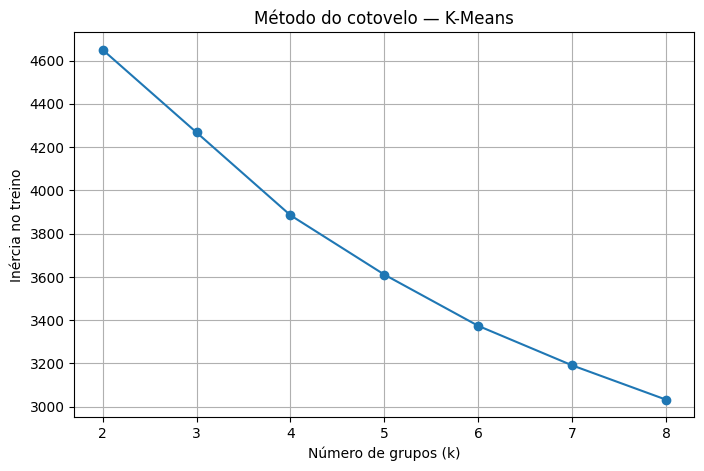

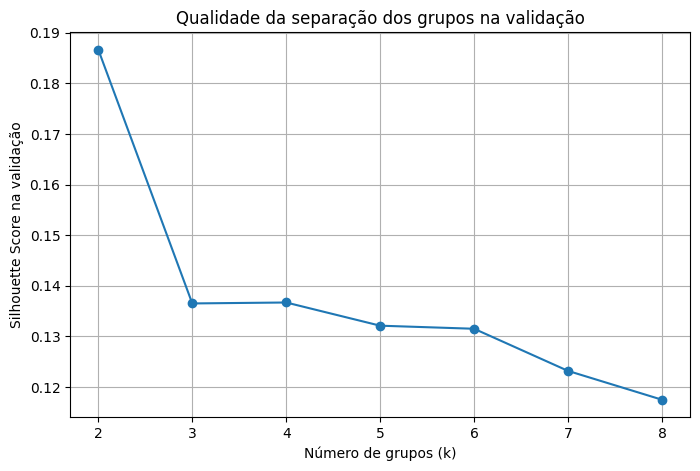

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

# Quantidades de grupos que vamos comparar
valores_k = range(2, 9)

resultados = []

for k in valores_k:
    # Treinar o K-Means apenas com os dados de treino
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X_train_scaled)

    # Inércia calculada no conjunto de treino
    inercia_treino = modelo.inertia_

    # Atribuir os registros de validação aos grupos aprendidos
    grupos_validacao = modelo.predict(X_val_scaled)

    # Calcular o Silhouette Score na validação
    quantidade_grupos_validacao = len(set(grupos_validacao))

    if 2 <= quantidade_grupos_validacao < len(X_val_scaled):
        silhouette_validacao = silhouette_score(
            X_val_scaled,
            grupos_validacao
        )
    else:
        silhouette_validacao = float("nan")

    resultados.append({
        "k": k,
        "inercia_treino": inercia_treino,
        "silhouette_validacao": silhouette_validacao
    })

# Exibir a comparação
resultados_df = pd.DataFrame(resultados)
display(resultados_df.round(4))

# Visualizar a inércia para observar o possível "cotovelo"
plt.figure(figsize=(8, 5))
plt.plot(
    resultados_df["k"],
    resultados_df["inercia_treino"],
    marker="o"
)
plt.xlabel("Número de grupos (k)")
plt.ylabel("Inércia no treino")
plt.title("Método do cotovelo — K-Means")
plt.xticks(list(valores_k))
plt.grid(True)
plt.show()

# Visualizar o Silhouette Score na validação
plt.figure(figsize=(8, 5))
plt.plot(
    resultados_df["k"],
    resultados_df["silhouette_validacao"],
    marker="o"
)
plt.xlabel("Número de grupos (k)")
plt.ylabel("Silhouette Score na validação")
plt.title("Qualidade da separação dos grupos na validação")
plt.xticks(list(valores_k))
plt.grid(True)
plt.show()

FAse 3. Próxima etapa — avaliar os grupos com k = 2

**Etapa 1.8 — Treinamento da configuração selecionada**

Com base na comparação realizada, vamos selecionar provisoriamente dois grupos para o K-Means.

Nesta etapa, o modelo será ajustado com os dados de treino. Em seguida, verificaremos a distribuição dos registros entre os grupos e calcularemos o Silhouette Score no conjunto de teste, reservado para a avaliação final.

Como se trata de aprendizagem não supervisionada, os grupos encontrados não possuem rótulos prévios. Será necessário analisar suas características antes de atribuir interpretações relacionadas às preferências turísticas.

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Definir a configuração selecionada
k_final = 2

# Treinar o modelo apenas com os dados de treino
modelo_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

modelo_final.fit(X_train_scaled)

# Atribuir cada registro de teste a um grupo
grupos_teste = modelo_final.predict(X_test_scaled)

# Avaliar a separação dos grupos no conjunto de teste
silhouette_teste = silhouette_score(
    X_test_scaled,
    grupos_teste
)

# Mostrar a quantidade de registros por grupo
distribuicao_grupos = pd.Series(
    grupos_teste
).value_counts().sort_index()

print("Número de grupos:", k_final)
print("\nSilhouette Score no teste:", round(silhouette_teste, 4))
print("\nQuantidade de registros por grupo no teste:")
display(distribuicao_grupos.to_frame(name="quantidade"))

print("\nPercentual por grupo no teste:")
display(
    (distribuicao_grupos / len(X_test) * 100)
    .round(2)
    .to_frame(name="percentual")
)

Número de grupos: 2

Silhouette Score no teste: 0.2185

Quantidade de registros por grupo no teste:


,quantidade
0,77
1,119



Percentual por grupo no teste:


,percentual
0,39.29
1,60.71


Etapa 1.9 — Interpretar os perfis encontrados

**Etapa 1.9 — Análise das características dos grupos**

O K-Means identificou dois grupos de registros. Nesta etapa, vamos comparar as médias das dez categorias turísticas em cada grupo, utilizando os dados de teste.

A comparação ajudará a identificar quais categorias apresentam avaliações relativamente maiores ou menores em cada grupo.

Os resultados serão interpretados como padrões de avaliação presentes nesta base de dados. Como a base é proveniente de avaliações de destinos da Ásia Oriental, não podemos afirmar que esses perfis representam diretamente os turistas de Navegantes.

Essa análise é uma etapa exploratória para avaliar o potencial da abordagem de agrupamento no futuro sistema de personalização da MOv.

In [16]:
# Reunir os dados originais do teste e os grupos identificados
resultado_teste = X_test.copy()
resultado_teste["grupo"] = grupos_teste

# Calcular a média de cada categoria em cada grupo
medias_por_grupo = resultado_teste.groupby("grupo").mean().T

# Comparar as médias dos grupos
display(medias_por_grupo.round(3))

grupo,0,1
galerias_arte,0.910,0.894
clubes_danca,1.538,1.284
bares_sucos,1.575,0.558
restaurantes,0.699,0.462
museus,1.263,0.718
resorts,2.241,1.487
parques_pícnic,3.188,3.176
praias,2.789,2.852
teatros,1.621,1.562
instituicoes_religiosas,2.548,2.971


Diferença entre as médias (grupo 1 menos grupo 0):


,diferenca
bares_sucos,-1.017
resorts,-0.755
museus,-0.544
clubes_danca,-0.253
restaurantes,-0.237
teatros,-0.059
galerias_arte,-0.016
parques_pícnic,-0.011
praias,0.063
instituicoes_religiosas,0.423


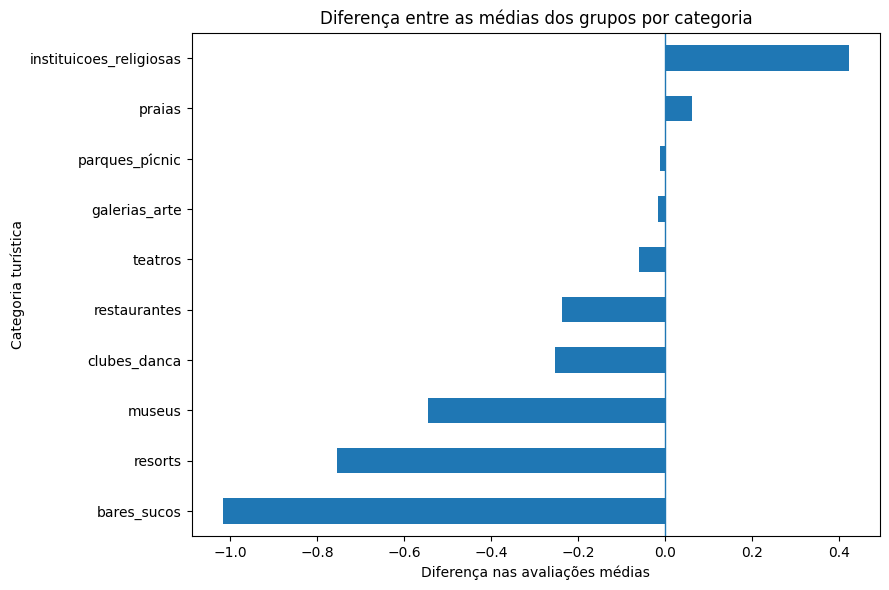

In [17]:
# Calcular a diferença entre as médias dos grupos
diferencas = (
    medias_por_grupo[1] - medias_por_grupo[0]
).sort_values()

print("Diferença entre as médias (grupo 1 menos grupo 0):")
display(diferencas.round(3).to_frame(name="diferenca"))

# Visualizar as diferenças
diferencas.plot(
    kind="barh",
    figsize=(9, 6),
    title="Diferença entre as médias dos grupos por categoria"
)

import matplotlib.pyplot as plt

plt.axvline(0, linewidth=1)
plt.xlabel("Diferença nas avaliações médias")
plt.ylabel("Categoria turística")
plt.tight_layout()
plt.show()

Etapa 1.10 — Comparar o modelo com e sem parques/piqueniques

Etapa 1.10 — Análise de uma variável de baixa variabilidade

A análise exploratória identificou que a variável parques_pícnic apresenta desvio-padrão muito baixo. Vamos comparar duas versões do K-Means: uma com as dez categorias originais e outra sem essa variável.

Para manter a comparação justa, usaremos as mesmas divisões de treino, validação e teste, padronizando cada versão exclusivamente com os dados de treino. O número de grupos será mantido em dois.

A comparação será baseada no Silhouette Score da validação e do teste. O objetivo é investigar se a variável de baixa variabilidade influencia a qualidade da separação, sem assumir antecipadamente que removê-la necessariamente melhorará o modelo.

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Criar versões dos dados sem a categoria de parques/piqueniques
coluna_remover = "parques_pícnic"

X_train_sem_parques = X_train.drop(columns=[coluna_remover])
X_val_sem_parques = X_val.drop(columns=[coluna_remover])
X_test_sem_parques = X_test.drop(columns=[coluna_remover])

# Padronizar a versão reduzida usando apenas o treino
scaler_sem_parques = StandardScaler()

X_train_reduzido = scaler_sem_parques.fit_transform(
    X_train_sem_parques
)
X_val_reduzido = scaler_sem_parques.transform(
    X_val_sem_parques
)
X_test_reduzido = scaler_sem_parques.transform(
    X_test_sem_parques
)

# Treinar o K-Means com as nove categorias
modelo_sem_parques = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

modelo_sem_parques.fit(X_train_reduzido)

# Avaliar na validação e no teste
grupos_val_reduzido = modelo_sem_parques.predict(X_val_reduzido)
grupos_teste_reduzido = modelo_sem_parques.predict(X_test_reduzido)

silhouette_val_reduzido = silhouette_score(
    X_val_reduzido,
    grupos_val_reduzido
)

silhouette_teste_reduzido = silhouette_score(
    X_test_reduzido,
    grupos_teste_reduzido
)

# Reunir os resultados para comparação
comparacao = pd.DataFrame([
    {
        "versao": "10 categorias",
        "silhouette_validacao": silhouette_score(
            X_val_scaled,
            modelo_final.predict(X_val_scaled)
        ),
        "silhouette_teste": silhouette_teste
    },
    {
        "versao": "9 categorias (sem parques)",
        "silhouette_validacao": silhouette_val_reduzido,
        "silhouette_teste": silhouette_teste_reduzido
    }
])

display(comparacao.round(4))

,versao,silhouette_validacao,silhouette_teste
0,10 categorias,0.1866,0.2185
1,9 categorias (sem parques),0.1694,0.2039


2. Próximo passo — registrar a decisão no Colab

Antes de avançar para a API, precisamos documentar o que testamos e por que escolhemos a versão final.

## Etapa 1.11 — Decisão sobre a configuração do modelo

**Algoritmo selecionado:** K-Means, com dois grupos.

**Configuração escolhida:** dez categorias turísticas, com padronização ajustada exclusivamente nos dados de treino.

**Critério de comparação:** Silhouette Score nos conjuntos de validação e teste.

**Resultados da versão com dez categorias:**
- Validação: 0,1866.
- Teste: 0,2185.

**Resultados da versão sem parques e piqueniques:**
- Validação: 0,1694.
- Teste: 0,2039.

**Justificativa:** a versão com dez categorias apresentou Silhouette Score superior tanto na validação quanto no teste. Por isso, optamos por mantê-la nesta etapa do projeto.

**Limitação:** os valores de Silhouette indicam separação limitada entre os grupos. Os agrupamentos representam padrões encontrados nesta base de avaliações e não devem ser considerados perfis comprovados dos turistas de Navegantes. A utilidade para personalização deverá ser validada com dados relevantes para o público da MOv.

Etapa 1.12 — Criar o pipeline de treinamento

### Etapa 1.12 — Construção do pipeline

Um pipeline reúne as etapas de preparação dos dados e treinamento em um único objeto.

Neste projeto, o pipeline terá duas etapas:
1. `StandardScaler`: padroniza as dez variáveis de entrada.
2. `KMeans`: identifica dois grupos de avaliações semelhantes.

O pipeline será treinado com os dados de treino originais, sem padronização manual prévia. Dessa forma, o próprio objeto guardará o padronizador e o modelo, permitindo reutilizar a sequência completa quando receber novos dados.

A validação e o teste continuarão reservados para avaliar o resultado, sem participar do ajuste do pipeline.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Reunir a padronização e o agrupamento em um pipeline
pipeline_mov = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    ))
])

# Treinar o pipeline com os dados originais de treino
pipeline_mov.fit(X_train)

# Atribuir grupos aos registros de teste
grupos_teste_pipeline = pipeline_mov.predict(X_test)

# Calcular o Silhouette Score no espaço padronizado
X_test_pipeline_scaled = pipeline_mov.named_steps[
    "scaler"
].transform(X_test)

silhouette_pipeline = silhouette_score(
    X_test_pipeline_scaled,
    grupos_teste_pipeline
)

print("Pipeline treinado com sucesso!")
print("Quantidade de variáveis:", X_train.shape[1])
print("Quantidade de grupos:", pipeline_mov.named_steps[
    "kmeans"
].n_clusters)
print(
    "Silhouette Score no teste:",
    round(silhouette_pipeline, 4)
)

Pipeline treinado com sucesso!
Quantidade de variáveis: 10
Quantidade de grupos: 2
Silhouette Score no teste: 0.2185


Etapa 1.13 — Salvar o pipeline

### Etapa 1.13 — Serialização do modelo

Vamos utilizar a biblioteca `joblib` para salvar o pipeline treinado em um arquivo.

O arquivo guardará tanto os parâmetros aprendidos pelo `StandardScaler` quanto os centros dos grupos aprendidos pelo K-Means. Isso permitirá carregar o pipeline posteriormente, sem repetir o treinamento a cada solicitação da API.

O artefato será salvo na pasta `models/`, conforme a organização prevista para o projeto.

In [20]:
from pathlib import Path
import joblib

# Criar a pasta destinada aos modelos
pasta_modelos = Path("models")
pasta_modelos.mkdir(parents=True, exist_ok=True)

# Definir o caminho do arquivo
caminho_pipeline = pasta_modelos / "mov_kmeans_pipeline.joblib"

# Salvar o pipeline treinado
joblib.dump(pipeline_mov, caminho_pipeline)

print("Pipeline salvo em:", caminho_pipeline)
print("Arquivo existe:", caminho_pipeline.exists())
print("Tamanho do arquivo:", caminho_pipeline.stat().st_size, "bytes")

Pipeline salvo em: models/mov_kmeans_pipeline.joblib
Arquivo existe: True
Tamanho do arquivo: 4345 bytes


Etapa 1.14 — Testar o carregamento do modelo salvo

Etapa 1.14 — Teste de carregamento e reutilização

Vamos carregar o pipeline salvo em disco e utilizá-lo para atribuir grupos a novos registros.

Esse teste verifica se o artefato pode ser reutilizado sem treinar novamente o modelo. Essa é uma condição importante para a integração futura com a API FastAPI.

O grupo retornado é um identificador técnico do agrupamento, não uma recomendação turística pronta. A interpretação e a utilização desses grupos precisarão ser definidas no desenvolvimento da MOv.

In [21]:
import joblib

# Carregar o pipeline salvo
pipeline_carregado = joblib.load(caminho_pipeline)

# Selecionar cinco registros do conjunto de teste
amostras = X_test.head(5)

# Atribuir grupos usando o pipeline carregado
grupos_previstos = pipeline_carregado.predict(amostras)

print("Pipeline carregado com sucesso!")
print("\nGrupos atribuídos às cinco amostras:")

for indice, grupo in enumerate(grupos_previstos, start=1):
    print(f"Amostra {indice}: grupo {grupo}")

# Conferir se o modelo carregado mantém as mesmas previsões
grupos_originais = pipeline_mov.predict(amostras)

print(
    "\nPrevisões idênticas após carregar:",
    (grupos_previstos == grupos_originais).all()
)

Pipeline carregado com sucesso!

Grupos atribuídos às cinco amostras:
Amostra 1: grupo 1
Amostra 2: grupo 1
Amostra 3: grupo 1
Amostra 4: grupo 0
Amostra 5: grupo 1

Previsões idênticas após carregar: True


Etapa 1.15 — Registrar a validação do artefato

Etapa 1.15 — Validação do pipeline salvo

O pipeline foi serializado com a biblioteca joblib no arquivo models/mov_kmeans_pipeline.joblib.

Após o carregamento do arquivo, o modelo foi utilizado para atribuir grupos a cinco registros do conjunto de teste. As atribuições foram comparadas com as produzidas pelo pipeline original.

Resultado: as previsões foram idênticas após o carregamento (True).

Conclusão: o artefato salvo pode ser carregado e reutilizado para realizar o agrupamento sem novo treinamento. Esse teste valida a consistência do carregamento para as cinco amostras verificadas; a integração com a API e os testes adicionais ainda serão realizados.

In [22]:
import sklearn
import joblib

print("Versão do scikit-learn:", sklearn.__version__)
print("Versão do joblib:", joblib.__version__)

Versão do scikit-learn: 1.6.1
Versão do joblib: 1.6.0


Célula 35 — Padronizar os nomes das características

Etapa 1.16 — Preparação para integração com a API
A API receberá as avaliações de preferências de um visitante e utilizará o pipeline treinado para atribuí-lo a um dos dois grupos identificados pelo K-Means.

Para facilitar a integração e evitar problemas com acentos nos nomes dos campos, vamos padronizar os nomes das características usando letras sem acentos e o padrão snake_case.

Essa padronização não altera os dados nem o algoritmo, mas exige que o pipeline seja treinado novamente com os nomes definitivos antes de ser salvo para uso na API.

In [23]:
print("Características utilizadas no modelo:")
print(X_model.columns.tolist())

Características utilizadas no modelo:
['galerias_arte', 'clubes_danca', 'bares_sucos', 'restaurantes', 'museus', 'resorts', 'parques_pícnic', 'praias', 'teatros', 'instituicoes_religiosas']


Célula 37 — Padronizar os nomes

Etapa 1.17 — Padronização dos campos de entrada
O padrão snake_case utiliza letras minúsculas e separa palavras com sublinhado. Também vamos evitar acentos nos nomes técnicos dos campos, facilitando sua utilização no Python, no FastAPI e na validação com Pydantic.

Célula 38 — Atualizar e conferir os nomes

In [24]:
X_model = X_model.rename(
    columns={"parques_pícnic": "parques_picnic"}
)

print("Características padronizadas:")
print(X_model.columns.tolist())

print("\nQuantidade de características:", len(X_model.columns))

Características padronizadas:
['galerias_arte', 'clubes_danca', 'bares_sucos', 'restaurantes', 'museus', 'resorts', 'parques_picnic', 'praias', 'teatros', 'instituicoes_religiosas']

Quantidade de características: 10


Célula 39 — Preparar a nova divisão dos dados

Etapa 1.18 — Reproduzir o treinamento com os nomes definitivos
Vamos manter a mesma estratégia usada anteriormente: 60% dos dados para treinamento, 20% para validação e 20% para teste, com random_state=42 para tornar a divisão reproduzível.

O StandardScaler será ajustado apenas nos dados de treinamento, evitando vazamento de informações dos conjuntos de validação e teste. Em seguida, o K-Means será treinado dentro de um Pipeline, que reúne o escalonamento e o agrupamento em um único objeto.

Célula 40 — Dividir os dados e treinar o pipeline

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Divisão: 80% para treino/validação e 20% para teste
X_temp, X_test = train_test_split(
    X_model,
    test_size=0.20,
    random_state=42
)

# Divisão dos 80% restantes: 60% treino e 20% validação
X_train, X_val = train_test_split(
    X_temp,
    test_size=0.25,
    random_state=42
)

# Pipeline com escalonamento e agrupamento
pipeline_mov = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    ))
])

# Treinamento somente com os dados de treino
pipeline_mov.fit(X_train)

# Avaliação na validação
grupos_val = pipeline_mov.predict(X_val)
X_val_escalado = pipeline_mov.named_steps["scaler"].transform(X_val)

silhueta_val = silhouette_score(
    X_val_escalado,
    grupos_val
)

# Avaliação final no teste
grupos_teste = pipeline_mov.predict(X_test)
X_test_escalado = pipeline_mov.named_steps["scaler"].transform(X_test)

silhueta_teste = silhouette_score(
    X_test_escalado,
    grupos_teste
)

print("Treinamento concluído.")
print("Características:", len(X_model.columns))
print("Treino:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)
print("Silhouette na validação:", round(silhueta_val, 4))
print("Silhouette no teste:", round(silhueta_teste, 4))
print(
    "Nomes do modelo:",
    pipeline_mov.named_steps["scaler"].feature_names_in_.tolist()
)

Treinamento concluído.
Características: 10
Treino: (588, 10)
Validação: (196, 10)
Teste: (196, 10)
Silhouette na validação: 0.1866
Silhouette no teste: 0.2185
Nomes do modelo: ['galerias_arte', 'clubes_danca', 'bares_sucos', 'restaurantes', 'museus', 'resorts', 'parques_picnic', 'praias', 'teatros', 'instituicoes_religiosas']


Célula 41 — Salvar a versão atualizada do pipeline

Etapa 1.19 — Persistência do modelo definitivo
Agora vamos salvar o pipeline recém-treinado no arquivo models/mov_kmeans_pipeline.joblib.

Esse arquivo contém o escalonador e o modelo K-Means. Assim, a API poderá carregar ambos juntos e receber novas avaliações sem precisar treinar o modelo a cada solicitação.

Célula 42 — Salvar e verificar o arquivo

In [26]:
from pathlib import Path
import joblib

pasta_modelos = Path("models")
pasta_modelos.mkdir(parents=True, exist_ok=True)

caminho_pipeline = pasta_modelos / "mov_kmeans_pipeline.joblib"

joblib.dump(pipeline_mov, caminho_pipeline)

print("Arquivo:", caminho_pipeline)
print("Arquivo existe:", caminho_pipeline.exists())
print("Tamanho:", caminho_pipeline.stat().st_size, "bytes")

Arquivo: models/mov_kmeans_pipeline.joblib
Arquivo existe: True
Tamanho: 4345 bytes


Célula 43 — Conferir se o arquivo salvo funciona
TIPO: TEXTO

Vamos testar o processo de salvar e carregar o modelo. Isso é importante porque a API utilizará o arquivo salvo, e não apenas o objeto que permanece na memória do Colab.

Célula 44 — Recarregar e comparar as previsões

In [27]:
pipeline_carregado = joblib.load(caminho_pipeline)

amostras = X_test.head(5)

grupos_original = pipeline_mov.predict(amostras)
grupos_carregado = pipeline_carregado.predict(amostras)

print("Previsões do pipeline original:", grupos_original)
print("Previsões do pipeline carregado:", grupos_carregado)

print(
    "Previsões idênticas:",
    (grupos_original == grupos_carregado).all()
)

Previsões do pipeline original: [1 1 1 0 1]
Previsões do pipeline carregado: [1 1 1 0 1]
Previsões idênticas: True


Célula 45 — Introdução à estrutura da API

Célula 46 — Instalar as dependências da API

Etapa 2.2 — Preparar o ambiente
O FastAPI será responsável pela API, o Uvicorn executará o servidor e o Pydantic validará os dados de entrada. Vamos instalar essas bibliotecas no ambiente atual do Colab.

Célula 47 — Instalação

In [28]:
%pip install fastapi uvicorn

Célula 50 — Criar a estrutura inicial da API

Etapa 2.3 — Organizar os arquivos do projeto
Vamos criar uma pasta chamada mov-api para reunir os arquivos da aplicação. Dentro dela, teremos a pasta models, que guardará o pipeline treinado.

mov-api/
└── models/
    └── mov_kmeans_pipeline.joblib

Célula 51 — Criar a pasta e copiar o modelo

In [29]:
from pathlib import Path
import shutil

# Pasta principal da API
pasta_projeto = Path("/content/mov-api")
pasta_modelos_api = pasta_projeto / "models"

# Criar as pastas
pasta_modelos_api.mkdir(parents=True, exist_ok=True)

# Localizar o pipeline treinado
arquivo_modelo = Path("/content/models/mov_kmeans_pipeline.joblib")

# Copiar o modelo para a pasta da API
if arquivo_modelo.exists():
    destino_modelo = pasta_modelos_api / "mov_kmeans_pipeline.joblib"
    shutil.copy2(arquivo_modelo, destino_modelo)

    print("Projeto:", pasta_projeto)
    print("Modelo copiado:", destino_modelo.exists())
    print("Tamanho:", destino_modelo.stat().st_size, "bytes")
else:
    print("Arquivo do modelo não encontrado:", arquivo_modelo)

Projeto: /content/mov-api
Modelo copiado: True
Tamanho: 4345 bytes


Célula 52 — Entender o schemas.py

Etapa 2.4 — Validar os dados de entrada
O Pydantic permite definir quais campos são obrigatórios e quais valores são aceitos. O FastAPI usa essas definições para validar automaticamente os dados enviados à API.

No nosso projeto, o visitante enviará dez avaliações, uma para cada categoria turística. Cada valor deverá estar entre 0 e 4, conforme a escala do conjunto de dados utilizado no treinamento.

Vamos usar Field para declarar os limites e um modelo chamado PreferenciasTurista para representar os dados recebidos.

Célula 53 — Criar o arquivo schemas.py

In [30]:
from pathlib import Path

pasta_projeto = Path("/content/mov-api")

conteudo_schema = '''from pydantic import BaseModel, Field


class PreferenciasTurista(BaseModel):
    galerias_arte: float = Field(ge=0, le=4)
    clubes_danca: float = Field(ge=0, le=4)
    bares_sucos: float = Field(ge=0, le=4)
    restaurantes: float = Field(ge=0, le=4)
    museus: float = Field(ge=0, le=4)
    resorts: float = Field(ge=0, le=4)
    parques_picnic: float = Field(ge=0, le=4)
    praias: float = Field(ge=0, le=4)
    teatros: float = Field(ge=0, le=4)
    instituicoes_religiosas: float = Field(ge=0, le=4)
'''

arquivo_schema = pasta_projeto / "schemas.py"
arquivo_schema.write_text(conteudo_schema, encoding="utf-8")

print("Arquivo criado:", arquivo_schema)
print("Arquivo existe:", arquivo_schema.exists())
print("\nConteúdo de schemas.py:\n")
print(arquivo_schema.read_text(encoding="utf-8"))

Arquivo criado: /content/mov-api/schemas.py
Arquivo existe: True

Conteúdo de schemas.py:

from pydantic import BaseModel, Field


class PreferenciasTurista(BaseModel):
    galerias_arte: float = Field(ge=0, le=4)
    clubes_danca: float = Field(ge=0, le=4)
    bares_sucos: float = Field(ge=0, le=4)
    restaurantes: float = Field(ge=0, le=4)
    museus: float = Field(ge=0, le=4)
    resorts: float = Field(ge=0, le=4)
    parques_picnic: float = Field(ge=0, le=4)
    praias: float = Field(ge=0, le=4)
    teatros: float = Field(ge=0, le=4)
    instituicoes_religiosas: float = Field(ge=0, le=4)



Célula 54 — Testar a validação dos dados

Etapa 2.5 — Verificar o esquema com Pydantic
Vamos conferir dois cenários:
- Entrada válida: todas as dez avaliações estão dentro da escala de 0 a 4.
- Entrada inválida: uma das avaliações está acima de 4.
Esse teste ajuda a entender como o Pydantic protege a API contra valores fora dos limites definidos.

Célula 55 — Executar o teste

In [31]:
import sys
from pathlib import Path

pasta_projeto = Path("/content/mov-api")
sys.path.insert(0, str(pasta_projeto))

from schemas import PreferenciasTurista
from pydantic import ValidationError

# Exemplo de entrada válida
dados_validos = {
    "galerias_arte": 2.0,
    "clubes_danca": 1.5,
    "bares_sucos": 1.0,
    "restaurantes": 2.5,
    "museus": 3.0,
    "resorts": 2.0,
    "parques_picnic": 4.0,
    "praias": 3.5,
    "teatros": 1.0,
    "instituicoes_religiosas": 2.5
}

preferencias = PreferenciasTurista(**dados_validos)

print("Entrada válida:", preferencias.model_dump())

# Exemplo de entrada inválida
dados_invalidos = dados_validos.copy()
dados_invalidos["praias"] = 5.0

try:
    PreferenciasTurista(**dados_invalidos)
except ValidationError as erro:
    print("\nEntrada inválida detectada corretamente.")
    print(erro)

Entrada válida: {'galerias_arte': 2.0, 'clubes_danca': 1.5, 'bares_sucos': 1.0, 'restaurantes': 2.5, 'museus': 3.0, 'resorts': 2.0, 'parques_picnic': 4.0, 'praias': 3.5, 'teatros': 1.0, 'instituicoes_religiosas': 2.5}

Entrada inválida detectada corretamente.
1 validation error for PreferenciasTurista
praias
  Input should be less than or equal to 4 [type=less_than_equal, input_value=5.0, input_type=float]
    For further information visit https://errors.pydantic.dev/2.14/v/less_than_equal
